# MLP for Burgers Equation
This notebook implements a pointwise MLP baseline for the Burgers equation dataset (train/test CSVs). The model maps (u_init(x), x, t) -> u(x,t) for each space-time point.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
# Load CSVs (relative to this notebook in Models/)
train_df = pd.read_csv("../data/burgers_train.csv")#.head(100)   # 400
test_df = pd.read_csv("../data/burgers_test.csv")#.head(25)      # 100
print('Train samples:', len(train_df), 'Test samples:', len(test_df))

Train samples: 400 Test samples: 100


In [3]:
train_df.head()

,A_initial,frequency_k,viscosity_nu,x_grid_0,x_grid_1,x_grid_2,x_grid_3,x_grid_4,x_grid_5,x_grid_6,...,u_15990,u_15991,u_15992,u_15993,u_15994,u_15995,u_15996,u_15997,u_15998,u_15999
0,1.182076,1.0,0.049586,0.0,0.032258,0.064516,0.096774,0.129032,0.16129,0.193548,...,0.487421,0.492226,0.489116,0.475150,0.446716,0.399856,0.331087,0.238925,0.125887,0.0
1,0.608668,1.0,0.025458,0.0,0.032258,0.064516,0.096774,0.129032,0.16129,0.193548,...,0.399475,0.406914,0.409592,0.405171,0.390206,0.359927,0.308506,0.230597,0.125025,0.0
2,0.978963,1.0,0.033205,0.0,0.032258,0.064516,0.096774,0.129032,0.16129,0.193548,...,0.491054,0.504132,0.511870,0.511177,0.497355,0.463698,0.401727,0.303231,0.165628,0.0
3,0.583833,1.0,0.046716,0.0,0.032258,0.064516,0.096774,0.129032,0.16129,0.193548,...,0.321332,0.315617,0.303962,0.285239,0.258382,0.222597,0.177646,0.124178,0.063980,0.0
4,0.571248,1.0,0.024586,0.0,0.032258,0.064516,0.096774,0.129032,0.16129,0.193548,...,0.385485,0.391887,0.393552,0.388255,0.372756,0.342637,0.292598,0.217918,0.117812,0.0


In [4]:
def prepare_mlp_pointwise_loaders(train_df, test_df, Nx=32, Nt=500, batch_size=4096, scale=True):
    """Prepare pointwise datasets: features=(u_init_at_x, x, t) -> target=u(x,t)."""

    def process(df):
        vals = df.values
        num_samples = vals.shape[0]
        total_mesh = Nx * Nt

        # columns layout: first 3 cols are metadata, then x_mesh, t_mesh, u_mesh
        x_flat = vals[:, 3 : 3 + total_mesh]
        t_flat = vals[:, 3 + total_mesh : 3 + 2 * total_mesh]
        u_flat = vals[:, 3 + 2 * total_mesh :]

        # reshape to (Samples, Nt, Nx)
        x_mesh = x_flat.reshape(num_samples, Nt, Nx)
        t_mesh = t_flat.reshape(num_samples, Nt, Nx)
        u_mesh = u_flat.reshape(num_samples, Nt, Nx)

        # initial condition per sample at t=0 (shape: Samples, Nx)
        u_init = u_mesh[:, 0, :]

        # expand u_init to time dimension to align with (Nt, Nx)
        u_init_exp = np.repeat(u_init[:, None, :], Nt, axis=1)  # (Samples, Nt, Nx)

        # Stack features and targets, then flatten to points: (Samples * Nt * Nx, features)
        features = np.stack([u_init_exp, x_mesh, t_mesh], axis=-1)  # (..., 3)
        targets = u_mesh[..., None]  # (..., 1)

        N_points = num_samples * Nt * Nx
        X = features.reshape(N_points, 3).astype(np.float32)
        y = targets.reshape(N_points, 1).astype(np.float32)

        return X, y

    X_train, y_train = process(train_df)
    X_test, y_test = process(test_df)

    if scale:
        x_scaler = StandardScaler()
        y_scaler = StandardScaler()
        X_train = x_scaler.fit_transform(X_train)
        X_test = x_scaler.transform(X_test)
        y_train = y_scaler.fit_transform(y_train)
        y_test = y_scaler.transform(y_test)
    else:
        x_scaler = None
        y_scaler = None

    train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
    test_ds = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, drop_last=False)

    return train_loader, test_loader, x_scaler, y_scaler

In [5]:
# Build loaders
Nx = 32
Nt = 500
train_loader, test_loader, x_scaler, y_scaler = prepare_mlp_pointwise_loaders(train_df, test_df, Nx=Nx, Nt=Nt, batch_size=16384)
print('Train loader batches:', len(train_loader), 'Test loader batches:', len(test_loader))

Train loader batches: 391 Test loader batches: 98


In [6]:
class MLPPointwise(nn.Module):
    def __init__(self, in_dim=3, hidden_dims=(16, 16), out_dim=1):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [7]:
# Loss utilities
class RelativeL2Loss(object):
    def __call__(self, y_pred, y_true):
        num_examples = y_pred.size(0)
        diff_norms = torch.norm(y_pred.reshape(num_examples, -1) - y_true.reshape(num_examples, -1), 2, 1)
        true_norms = torch.norm(y_true.reshape(num_examples, -1), 2, 1)
        return torch.mean(diff_norms / (true_norms + 1e-8))

In [8]:
# Training routine
def train_mlp(model, train_loader, test_loader, epochs=10, lr=1e-3, device='cpu'):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = RelativeL2Loss()  #nn.MSELoss()
    rel2 = RelativeL2Loss()

    train_losses = []
    val_losses = []

    for epoch in range(1, epochs+1):
        model.train()
        running = 0.0
        cnt = 0
        for Xb, yb in train_loader:
            Xb = Xb.to(device)
            yb = yb.to(device)
            optimizer.zero_grad()
            out = model(Xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * Xb.size(0)
            cnt += Xb.size(0)
        train_epoch_loss = running / cnt
        train_losses.append(train_epoch_loss)

        # validation (compute relative L2 on full test set)
        model.eval()
        val_running = 0.0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb = Xb.to(device)
                yb = yb.to(device)
                out = model(Xb)
                val_running += rel2(out, yb).item() * Xb.size(0)
        val_epoch = val_running / (len(test_loader.dataset))
        val_losses.append(val_epoch)

        if epoch == 1 or epoch % 5 == 0:
            print(f'Epoch {epoch}/{epochs} | Train RelL2: {train_epoch_loss:.6f} | Val RelL2: {val_epoch:.6f}')

    return model, train_losses, val_losses

In [9]:
# Hyperparameter search definitions
PARAM_SPACE = {
    "hidden_dims": [(16, 16), (32, 32)],
    "lr": [1e-3, 5e-4, 3e-4],
    "epochs": [5],
    "weight_decay": [0.0, 1e-5, 1e-4],
}

def sample_hyperparameters(space):
    return {k: random.choice(v) for k, v in space.items()}

NUM_SEARCH_TRIALS = 5
print(f"Random search will evaluate {NUM_SEARCH_TRIALS} candidate MLP configs.")

Random search will evaluate 5 candidate MLP configs.


In [10]:
# Random search and final retraining
device = 'cpu'

best_overall_loss = float("inf")
best_overall_config = None
search_history = []

print("Starting MLP random search...")
for trial in range(NUM_SEARCH_TRIALS):
    config = sample_hyperparameters(PARAM_SPACE)
    print(f"\n--- Trial {trial + 1}/{NUM_SEARCH_TRIALS} ---")
    print(f"Testing Config: {config}")

    trial_model = MLPPointwise(in_dim=3, hidden_dims=config["hidden_dims"], out_dim=1)
    _, _, val_hist = train_mlp(
        trial_model,
        train_loader,
        test_loader,
        epochs=config["epochs"],
        lr=config["lr"],
        device=device,
    )

    score = val_hist[-1]
    search_history.append({"config": config, "val_rel_l2": score})
    print(f"Trial final Val RelL2: {score:.6f}")

    if score < best_overall_loss:
        best_overall_loss = score
        best_overall_config = config
        print(" New overall best configuration found!")

print("\nRANDOM SEARCH COMPLETE")
print(f"Best Relative L2 Error: {best_overall_loss:.6f}")
print(f"Best Configuration: {best_overall_config}")

Starting MLP random search...

--- Trial 1/5 ---
Testing Config: {'hidden_dims': (32, 32), 'lr': 0.0003, 'epochs': 5, 'weight_decay': 0.0}
Epoch 1/5 | Train RelL2: 1.048046 | Val RelL2: 0.942461
Epoch 5/5 | Train RelL2: 0.748611 | Val RelL2: 0.709808
Trial final Val RelL2: 0.709808
 New overall best configuration found!

--- Trial 2/5 ---
Testing Config: {'hidden_dims': (16, 16), 'lr': 0.0005, 'epochs': 5, 'weight_decay': 0.0001}
Epoch 1/5 | Train RelL2: 1.512281 | Val RelL2: 0.960412
Epoch 5/5 | Train RelL2: 0.777545 | Val RelL2: 0.730574
Trial final Val RelL2: 0.730574

--- Trial 3/5 ---
Testing Config: {'hidden_dims': (32, 32), 'lr': 0.001, 'epochs': 5, 'weight_decay': 0.0}
Epoch 1/5 | Train RelL2: 0.958469 | Val RelL2: 0.810957
Epoch 5/5 | Train RelL2: 0.700342 | Val RelL2: 0.662530
Trial final Val RelL2: 0.662530
 New overall best configuration found!

--- Trial 4/5 ---
Testing Config: {'hidden_dims': (16, 16), 'lr': 0.0005, 'epochs': 5, 'weight_decay': 0.0}
Epoch 1/5 | Train RelL

In [11]:
# Retrain the best model with a longer schedule
FINAL_EPOCHS = 40
print("\n================ RETRAINING BEST MODEL ================")
print(f"Using Configuration: {best_overall_config}")
final_model = MLPPointwise(in_dim=3, hidden_dims=best_overall_config["hidden_dims"], out_dim=1)
final_model, train_hist, val_hist = train_mlp(
    final_model,
    train_loader,
    test_loader,
    epochs=FINAL_EPOCHS,
    lr=best_overall_config["lr"],
    device=device,
)

# Save final model weights
os.makedirs('../Models', exist_ok=True)
save_path = '../Models/best_mlp_burgers.pth'
torch.save(final_model.state_dict(), save_path)
print('Model saved to', save_path)


================ RETRAINING BEST MODEL ================
Using Configuration: {'hidden_dims': (32, 32), 'lr': 0.001, 'epochs': 5, 'weight_decay': 0.0}
Epoch 1/40 | Train RelL2: 1.025468 | Val RelL2: 0.781708
Epoch 5/40 | Train RelL2: 0.679754 | Val RelL2: 0.599111
Epoch 10/40 | Train RelL2: 0.444436 | Val RelL2: 0.624011
Epoch 15/40 | Train RelL2: 0.396996 | Val RelL2: 0.405900
Epoch 20/40 | Train RelL2: 0.414026 | Val RelL2: 0.381583
Epoch 25/40 | Train RelL2: 0.344812 | Val RelL2: 0.318023
Epoch 30/40 | Train RelL2: 0.311216 | Val RelL2: 0.305764
Epoch 35/40 | Train RelL2: 0.271272 | Val RelL2: 0.264686
Epoch 40/40 | Train RelL2: 0.278820 | Val RelL2: 0.281073
Model saved to ../Models/best_mlp_burgers.pth


In [12]:
# Quick evaluation: predict a few samples and compare mean dynamics
# We'll reconstruct predictions sample-wise by querying the trained MLP over all points
def predict_full_samples(model, df, Nx=32, Nt=500, x_scaler=None, y_scaler=None, device='cpu'):
    vals = df.values
    num_samples = vals.shape[0]
    total_mesh = Nx * Nt
    x_flat = vals[:, 3 : 3 + total_mesh]
    t_flat = vals[:, 3 + total_mesh : 3 + 2 * total_mesh]
    u_flat = vals[:, 3 + 2 * total_mesh :]
    x_mesh = x_flat.reshape(num_samples, Nt, Nx)
    t_mesh = t_flat.reshape(num_samples, Nt, Nx)
    u_mesh = u_flat.reshape(num_samples, Nt, Nx)
    u_init = u_mesh[:, 0, :]

    u_init_exp = np.repeat(u_init[:, None, :], Nt, axis=1)
    features = np.stack([u_init_exp, x_mesh, t_mesh], axis=-1).reshape(num_samples * Nt * Nx, 3).astype(np.float32)
    if x_scaler is not None:
        features = x_scaler.transform(features)
    with torch.no_grad():
        model.to(device)
        X = torch.from_numpy(features).to(device)
        preds = model(X).cpu().numpy()
    if y_scaler is not None:
        preds = y_scaler.inverse_transform(preds)
    preds = preds.reshape(num_samples, Nt, Nx)
    return preds, u_mesh

preds, targets = predict_full_samples(
    final_model,
    test_df,
    Nx=Nx,
    Nt=Nt,
    x_scaler=x_scaler,
    y_scaler=y_scaler,
    device=device,
)
print('Pred shape:', preds.shape, 'Target shape:', targets.shape)

Pred shape: (100, 500, 32) Target shape: (100, 500, 32)


In [13]:
# Plot mean dynamics and training results
output_dir = "mlp_burgers_plots"
os.makedirs(output_dir, exist_ok=True)

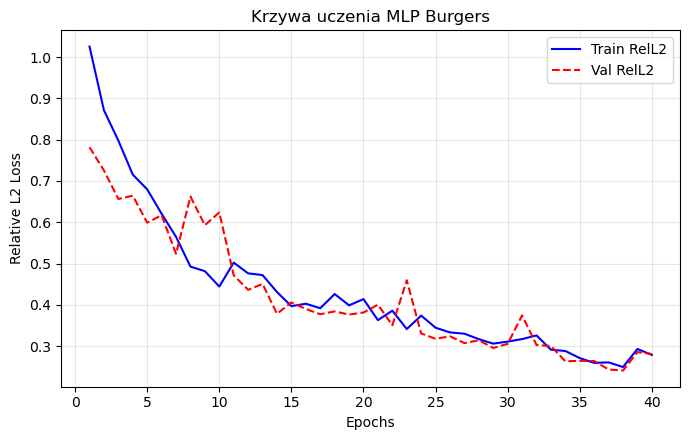

In [14]:
# Loss curves for final retraining
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, len(train_hist) + 1), train_hist, label="Train RelL2", color="blue", linewidth=1.5)
plt.plot(range(1, len(val_hist) + 1), val_hist, label="Val RelL2", color="red", linestyle="--", linewidth=1.5)
plt.xlabel("Epochs")
plt.ylabel("Relative L2 Loss")
plt.title("Krzywa uczenia MLP Burgers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
train_plot_path = os.path.join(output_dir, "mlp_loss_history.png")
plt.savefig(train_plot_path, dpi=300, bbox_inches="tight")
plt.show()

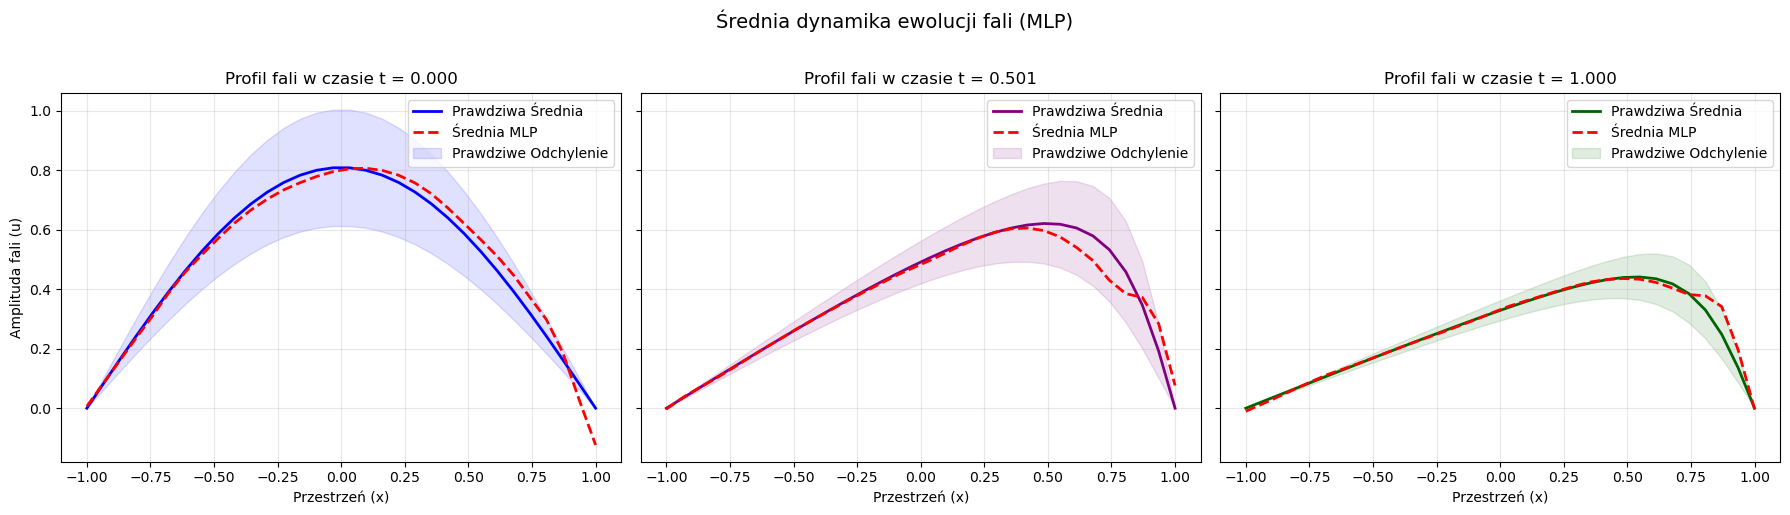

In [15]:
# Plot selected time slices vs. mean and std dev
time_axis = np.linspace(0, 1, Nt)
x_axis = np.linspace(-1, 1, Nx)

mean_target = targets.mean(axis=0)
mean_pred = preds.mean(axis=0)
std_target = targets.std(axis=0)

time_slices = [0, len(time_axis) // 2, -1]
slice_colors = ["blue", "purple", "darkgreen"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for idx, t_idx in enumerate(time_slices):
    actual_t = time_axis[t_idx]
    axes[idx].plot(
        x_axis,
        mean_target[t_idx],
        color=slice_colors[idx],
        linewidth=2,
        label="Prawdziwa Średnia",
    )
    axes[idx].plot(
        x_axis,
        mean_pred[t_idx],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Średnia MLP",
    )
    axes[idx].fill_between(
        x_axis,
        mean_target[t_idx] - std_target[t_idx],
        mean_target[t_idx] + std_target[t_idx],
        color=slice_colors[idx],
        alpha=0.12,
        label="Prawdziwe Odchylenie",
    )
    axes[idx].set_title(f"Profil fali w czasie t = {actual_t:.3f}")
    axes[idx].set_xlabel("Przestrzeń (x)")
    if idx == 0:
        axes[idx].set_ylabel("Amplituda fali (u)")
    axes[idx].legend(loc="upper right")
    axes[idx].grid(True, alpha=0.3)
plt.suptitle("Średnia dynamika ewolucji fali (MLP)", fontsize=14, y=1.02)
plt.tight_layout()
slice_plot_path = os.path.join(output_dir, "mlp_slice_comparison.png")
plt.savefig(slice_plot_path, dpi=300, bbox_inches="tight")
plt.show()

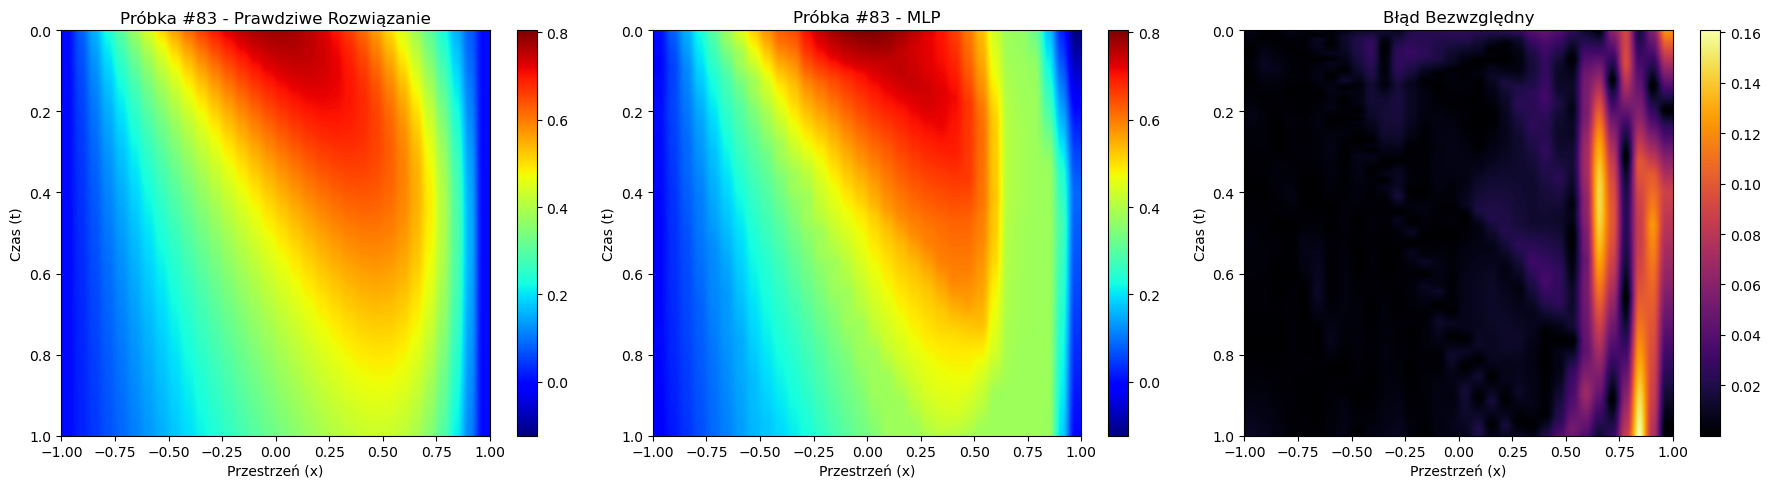

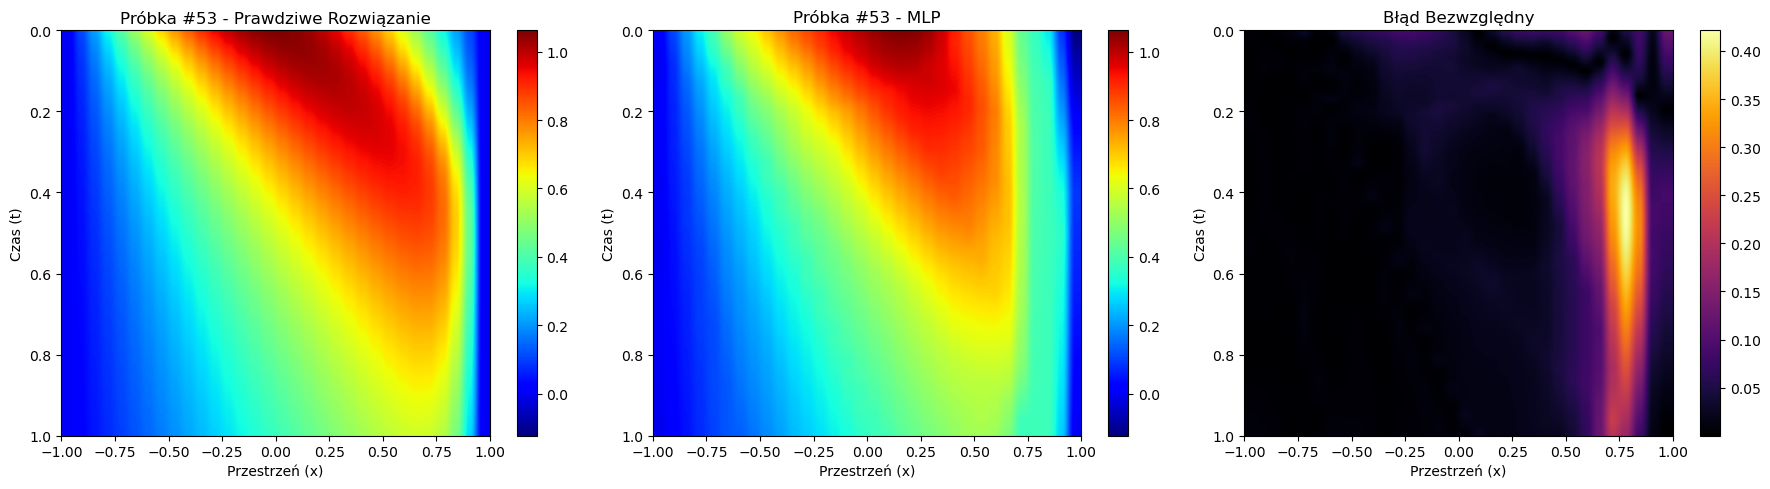

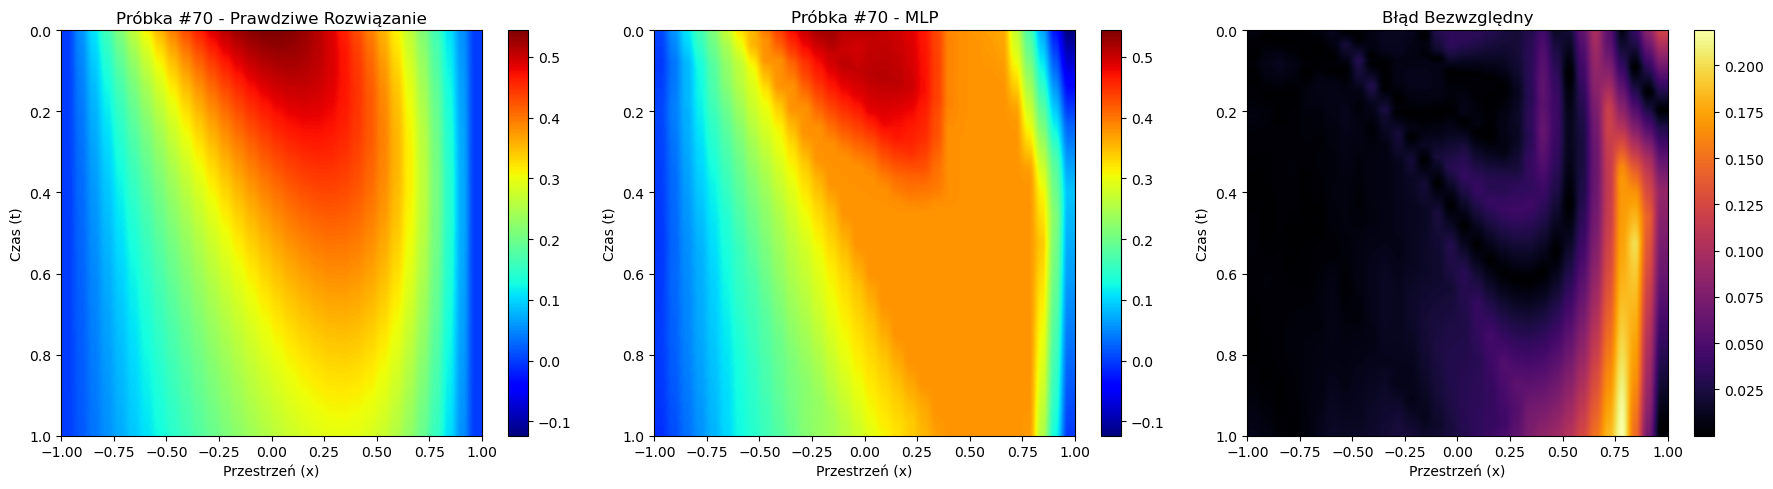

In [16]:
# Full sample contour comparison for a few random examples
abs_error_map = np.abs(targets - preds)
np.random.seed(42)
random_indices = np.random.choice(len(preds), size=3, replace=False)
for sample_idx in random_indices:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    vmin = min(targets[sample_idx].min(), preds[sample_idx].min())
    vmax = max(targets[sample_idx].max(), preds[sample_idx].max())

    im0 = axes[0].imshow(
        targets[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )
    axes[0].set_title(f"Próbka #{sample_idx} - Prawdziwe Rozwiązanie")
    axes[0].set_xlabel("Przestrzeń (x)")
    axes[0].set_ylabel("Czas (t)")
    fig.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(
        preds[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )
    axes[1].set_title(f"Próbka #{sample_idx} - MLP")
    axes[1].set_xlabel("Przestrzeń (x)")
    axes[1].set_ylabel("Czas (t)")
    fig.colorbar(im1, ax=axes[1])

    im2 = axes[2].imshow(
        abs_error_map[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="inferno",
    )
    axes[2].set_title("Błąd Bezwzględny")
    axes[2].set_xlabel("Przestrzeń (x)")
    axes[2].set_ylabel("Czas (t)")
    fig.colorbar(im2, ax=axes[2])

    plt.tight_layout()
    sample_plot_path = os.path.join(output_dir, f"mlp_sample_{sample_idx}_contour.png")
    plt.savefig(sample_plot_path, dpi=300, bbox_inches="tight")
    plt.show()